In [102]:
import pandas as pd

In [103]:
df = pd.read_csv("../datasetMerger/df_merge.csv")
df.head()


,playerID,year,tmID,Performance_Per_Game,award,franchID,confID,rank,playoff,seeded,...,stint,won_coach,lost_coach,post_wins_coach,post_losses_coach,height,weight,birthDate,post_season_team_W,post_season_team_L
0,abrossv01w,2,MIN,12.346153,NaN,MIN,WE,6.0,0,0.0,...,0,12.0,20.0,0.0,0.0,74.0,169.0,1980-07-09,NaN,NaN
1,abrossv01w,3,MIN,8.259259,NaN,MIN,WE,8.0,0,0.0,...,1,6.0,13.0,0.0,0.0,74.0,169.0,1980-07-09,NaN,NaN
2,abrossv01w,3,MIN,8.259259,NaN,MIN,WE,8.0,0,0.0,...,2,4.0,9.0,0.0,0.0,74.0,169.0,1980-07-09,NaN,NaN
3,abrossv01w,4,MIN,10.133333,NaN,MIN,WE,4.0,1,0.0,...,0,18.0,16.0,1.0,2.0,74.0,169.0,1980-07-09,1.0,2.0
4,abrossv01w,5,MIN,6.636363,NaN,MIN,WE,3.0,1,0.0,...,0,18.0,16.0,0.0,2.0,74.0,169.0,1980-07-09,0.0,2.0


# Fixing a Slight Inconsistency


### We noticed that on year6, two teams managed to win the playoffs. To remove that impossibility we decided to manually change the loser to be effectively assigned the loss of the finals game

In [104]:
df.loc[(df['tmID'] == 'CON') & (df['year'] == 6), 'finals'] = 'L'


# Data Reduction


In [105]:
# We developed PER stats por each player thinking that it was a good way to evaluate the performance of each player of each team on each of the seasons
"""
For PER calculations, all the stats of the player are considered to give a numerical result of what should be his performance throughout the season
As we know the totals of teams are the sum of all the players involved SOOOOO we should possibly substitute the stats of the team by the mean of
the performance of the players of that team?

"""

columns_to_drop = ["playerID", "name", "o_fgm", "o_fga", "o_ftm", "o_fta", "o_3pm", "o_3pa", 
                   "o_oreb", "o_dreb", "o_reb", "o_asts", "o_pf", "o_stl", "o_to", "o_blk", "o_pts",
                   "d_fgm", "d_fga", "d_ftm", "d_fta", "d_3pm", "d_3pa", "d_oreb", "d_dreb", "d_reb",
                   "d_asts", "d_pf", "d_stl", "d_to", "d_blk", "d_pts", "playerID"]


df = df.drop(columns=columns_to_drop)

team_performance = df.groupby(['tmID', 'year']).agg(
    confID=('confID','first'),
    Team_Performance_Mean_Current_Season=('Performance_Per_Game', 'median'), #dont know if its better to keep mean or median
    #Team_Performance_Median=('Performance_Per_Game', 'median'),

    homeW=('homeW', 'first'),       
    homeL=('homeL', 'first'),
    awayW=('awayW', 'first'),
    awayL=('awayL', 'first'),
    confW=('confW', 'first'),
    confL=('confL', 'first'),
    playoff=('playoff', 'first'),
    firstRound=('firstRound', 'first'),
    semis=('semis', 'first'),
    finals=('finals', 'first'),
    won_team=('won_team', 'first'),
    lost_team=('lost_team', 'first'),
    GP=('GP', 'first'),
    attend=('attend', 'first'),       
    arena=('arena', 'first'),
    coachID=('coachID', 'first'),
    stint=('stint', 'first'),
    won_coach=('won_coach', 'first'),
    lost_coach=('lost_coach', 'first'),
    post_wins_coach=('post_wins_coach', 'first'),
    post_losses_coach=('post_losses_coach', 'first'),
    post_season_team_W=('post_season_team_W', 'first'),
    post_season_team_L=('post_season_team_L', 'first'),
    height=('height', 'mean'),      
    weight=('weight', 'mean'),      
    birthDate=('birthDate', 'first') 
).reset_index()


team_performance['Team_Performance_Mean_Current_Season'] = team_performance['Team_Performance_Mean_Current_Season'].round(1)

#team_performance['Team_Performance_Median'] = team_performance['Team_Performance_Median'].round(1)
col_drop = ["birthDate","stint"]
team_performance = team_performance.drop(columns=col_drop)
team_performance.to_csv("featurePrep.csv", index=False)


print(team_performance.head())


  tmID  year confID  Team_Performance_Mean_Current_Season  homeW  homeL  \
0  ATL     9     EA                                   5.7    1.0   16.0   
1  ATL    10     EA                                   6.9   12.0    5.0   
2  ATL    11     EA                                   NaN    NaN    NaN   
3  CHA     1     EA                                   5.9    5.0   11.0   
4  CHA     2     EA                                   6.3   11.0    5.0   

   awayW  awayL  confW  confL  ...               arena     coachID won_coach  \
0    3.0   14.0    2.0   18.0  ...       Philips Arena  meadoma99w       4.0   
1    6.0   11.0   10.0   12.0  ...       Philips Arena  meadoma99w      18.0   
2    NaN    NaN    NaN    NaN  ...       Philips Arena  meadoma99w       NaN   
3    3.0   13.0    5.0   16.0  ...  Charlotte Coliseum  dunntr01wc       8.0   
4    7.0    9.0   15.0    6.0  ...  Charlotte Coliseum  donovan99w      18.0   

  lost_coach  post_wins_coach  post_losses_coach  post_season_team_W

In [106]:
"""
team_awards_count = df.groupby(['tmID', 'year']).agg(
    num_awards_of_current_season=('award', 'count') 
).reset_index()

team_performance = team_performance.merge(team_awards_count, on=['tmID', 'year'], how='left')
team_performance['num_awards_of_current_season'] = team_performance['num_awards_of_current_season'].round()


#team_performance.to_csv("featurePrep_with_awards.csv", index=False)
print(team_performance[['tmID', 'year', 'num_awards_of_current_season']].head())
"""

'\nteam_awards_count = df.groupby([\'tmID\', \'year\']).agg(\n    num_awards_of_current_season=(\'award\', \'count\') \n).reset_index()\n\nteam_performance = team_performance.merge(team_awards_count, on=[\'tmID\', \'year\'], how=\'left\')\nteam_performance[\'num_awards_of_current_season\'] = team_performance[\'num_awards_of_current_season\'].round()\n\n\n#team_performance.to_csv("featurePrep_with_awards.csv", index=False)\nprint(team_performance[[\'tmID\', \'year\', \'num_awards_of_current_season\']].head())\n'

In [22]:
award_values = {
    "Most Valuable Player": 10,
    "WNBA Finals Most Valuable Player": 9,
    "Coach of the Year": 1,
    "Defensive Player of the Year": 7,
    "All-Star Game Most Valuable Player": 6,
    "WNBA All-Decade Team": 5,
    "Most Improved Player": 4,
    "WNBA All Decade Team Honorable Mention": 3,
    "Rookie of the Year": 2,
    "Sixth Woman of the Year": 1,
    "Kim Perrot Sportsmanship Award": 0,
}

df = pd.read_csv("../datasetMerger/df_merge.csv")

df['trophyPower'] = 0
for player_id in df['playerID'].unique():
    player_data = df[df['playerID'] == player_id]
    player_data = player_data.sort_values(by='year')

    previous_power = 0
    for index, row in player_data.iterrows():
        award = row['award']
        award_value = award_values.get(award, 0)
        current_power = previous_power + award_value
        df.loc[index, 'trophyPower'] = current_power
        previous_power = current_power


df = df.drop(columns=['award', 'name', 'playerID'])
team_award_power = df.groupby(['tmID', 'year']).agg(
    team_award_power=('trophyPower', 'sum')  
).reset_index()
team_award_power['last_year_team_award_power'] = team_award_power.groupby('tmID')['team_award_power'].shift(1)
team_performance = team_performance.merge(team_award_power[['tmID', 'year', 'last_year_team_award_power']], 
                                           on=['tmID', 'year'], how='left')

team_performance['last_year_team_award_power'] = team_performance['last_year_team_award_power'].fillna(-1)
team_performance = team_performance.sort_values(by=['year', 'tmID'], ascending=[True, True])
team_performance.to_csv("featurePrep.csv", index=False)
print(team_performance[['tmID', 'year', 'last_year_team_award_power']].head())


NameError: name 'team_performance' is not defined

In [108]:
team_performance['isChampion'] = (team_performance['playoff'] == 1) & (team_performance['finals'] == 'W')
team_performance['lastYearChampion'] = team_performance.groupby('tmID')['isChampion'].shift(1).fillna(0).astype(int)
## Cleaning columns we deem irrelevant
team_performance.drop(columns=['isChampion','firstRound','semis','finals'],inplace=True)
team_performance.to_csv('featurePrep.csv', index=False)





# Some more feature engineering

In [109]:
# More Feature Engineering

team_performance['winPercentage'] = (team_performance['homeW'] + team_performance['awayW']) / (team_performance['homeW'] + team_performance['homeL'] + team_performance['awayW'] + team_performance['awayL'])
team_performance['confWinPercentage'] = team_performance['confW'] / (team_performance['confW'] + team_performance['confL'])
team_performance['coachWinRate'] = team_performance['won_coach'] / (team_performance['won_coach'] + team_performance['lost_coach'])
team_performance['homeWinRate'] = team_performance['homeW'] / (team_performance['homeW'] + team_performance['homeL'])
team_performance['avgAttendance'] = team_performance['attend'] / team_performance['GP']
columns_to_drop = [
    'homeW', 'homeL', 'awayW', 'awayL', 'confW', 'confL', 
    'won_coach', 'lost_coach', 'attend', 'GP', 'won_team', 'lost_team' , 'arena'
]
team_performance = team_performance.drop(columns=columns_to_drop, errors='ignore')
team_performance.to_csv('featurePrep.csv', index=False)


In [ ]:

team_performance['last_year_team_performance'] = team_performance.groupby('tmID')['Team_Performance_Mean_Current_Season'].shift(1)
team_performance['last_year_team_performance'] = team_performance['last_year_team_performance'].fillna(-1)
team_performance = team_performance.drop(columns=['Team_Performance_Mean_Current_Season'])
team_performance['last_year_win_percentage'] = team_performance.groupby('tmID')['winPercentage'].shift(1)
team_performance['last_year_win_percentage'] = team_performance['last_year_win_percentage'].fillna(-1)

win_weight = 0.7
attendance_weight = 0.3
max_attendance = team_performance['avgAttendance'].max()
team_performance['last_year_attendance'] = team_performance.groupby('tmID')['avgAttendance'].shift(1)


team_performance['scaled_attendance'] = team_performance.apply(
    lambda row: row['last_year_attendance'] / max_attendance
    if row['year'] == 11 and pd.isna(row['avgAttendance'])
    else row['avgAttendance'] / max_attendance if not pd.isna(row['avgAttendance'])
    else 0, 
    axis=1
)

team_performance['last_year_team_performance'] = team_performance.apply(
    lambda row: -1 if row['last_year_team_performance'] == -1 else (
        row['last_year_team_performance'] +
        win_weight * row['last_year_win_percentage'] +
        attendance_weight * row['scaled_attendance']
    ),
    axis=1
)

team_performance = team_performance.drop(columns=['scaled_attendance', 'last_year_attendance'], errors='ignore')
print(team_performance[team_performance['year'] == 11][['tmID', 'year', 'last_year_team_performance']])


team_performance = team_performance.drop(columns=['winPercentage'])
team_performance['coachPostSuccess'] = team_performance.apply(
    lambda row: row['post_wins_coach'] / (row['post_wins_coach'] + row['post_losses_coach']) 
    if (row['post_wins_coach'] + row['post_losses_coach']) > 0 else 0, 
    axis=1
)

team_performance['previous_year_coach_post_success'] = (
    team_performance.groupby('coachID')['coachPostSuccess'].shift(1).fillna(-1)
)
columns_to_drop = ['post_wins_coach', 'post_losses_coach', 'coachPostSuccess', 'post_season_team_W', 'post_season_team_L']
team_performance = team_performance.drop(columns=columns_to_drop, errors='ignore')
team_performance = team_performance.round(1)
team_performance.to_csv('featurePrep.csv', index=False)

print(team_performance.head())


    tmID  year  last_year_team_performance
2    ATL    11                    7.402091
14   CHI    11                    6.302225
26   CON    11                    7.555206
56   IND    11                    6.299940
67   LAS    11                   10.262921
81   MIN    11                    7.427787
92   NYL    11                    6.649107
106  PHO    11                   11.531333
127  SAS    11                    8.648190
138  SEA    11                    7.857559
139  TUL    11                   -1.000000
153  WAS    11                    6.439346
   tmID  year confID  playoff     coachID  height  weight  \
3   CHA     1     EA        0  dunntr01wc    71.7   168.8   
15  CLE     1     EA        1  hugheda99w    70.9   162.8   
27  DET     1     EA        0  liebena01w    71.5   162.9   
37  HOU     1     WE        1  chancva99w    72.1   166.2   
46  IND     1     EA        0  donovan99w    72.3   168.0   

    last_year_team_award_power  lastYearChampion  confWinPercentage  \
3  

In [111]:
print(team_performance[team_performance['year'] == 11].head())


   tmID  year confID  playoff     coachID  height  weight  \
2   ATL    11     EA        0  meadoma99w    72.9   160.6   
14  CHI    11     EA        0  chatmda99w    73.0   169.9   
26  CON    11     EA        0  thibami99w    71.9   168.6   
56  IND    11     EA        0  dunnli99wc    71.5   169.1   
67  LAS    11     WE        0  gilloje01w    72.8   171.7   

    last_year_team_award_power  lastYearChampion  confWinPercentage  \
2                         21.0                 0                NaN   
14                         2.0                 0                NaN   
26                         0.0                 0                NaN   
56                        52.0                 0                NaN   
67                       147.0                 0                NaN   

    coachWinRate  homeWinRate  avgAttendance  last_year_team_performance  \
2            NaN          NaN            NaN                         7.4   
14           NaN          NaN            NaN          

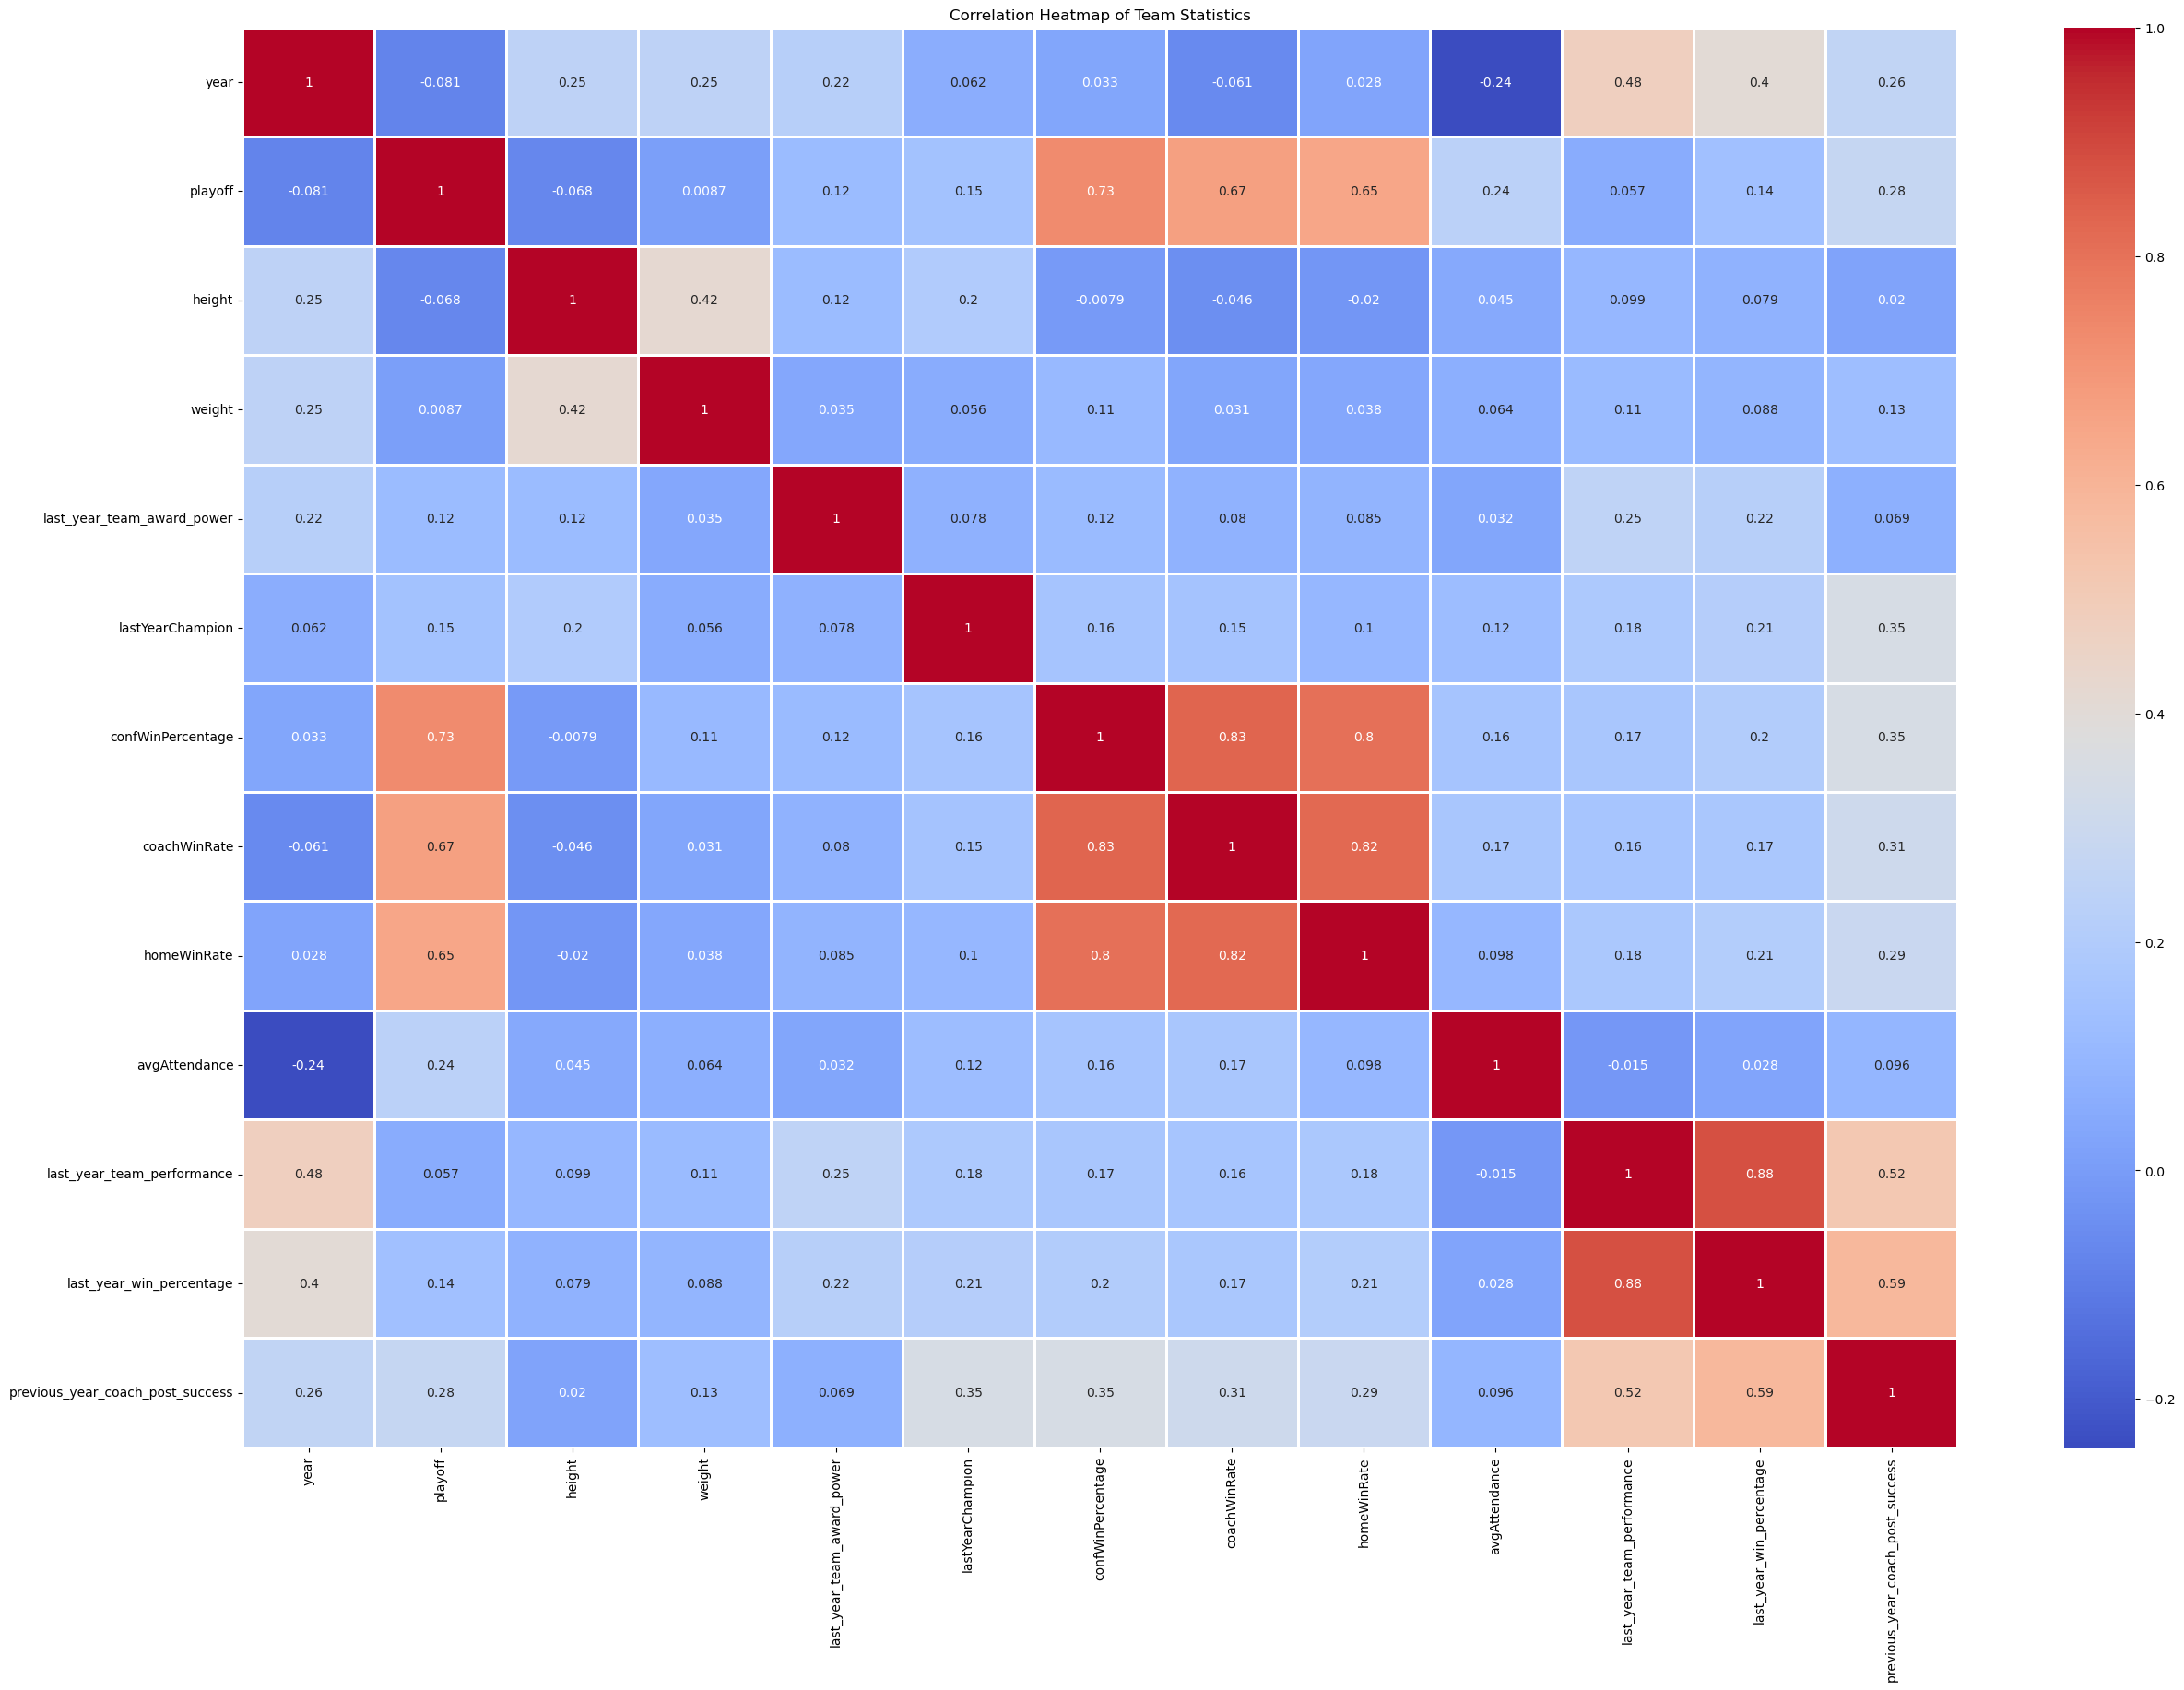

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt

team_performance = team_performance.loc[:, (team_performance != 0).any(axis=0)] # Eliminar Noisy Columns (que so têm 0)


data_numeric=team_performance.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()


plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()

# Analysing the Correlation Map 

We notice that win percentages in general have a strong correlation to whether or not a team achieves the playoffs and they even correlate a lot between themselves

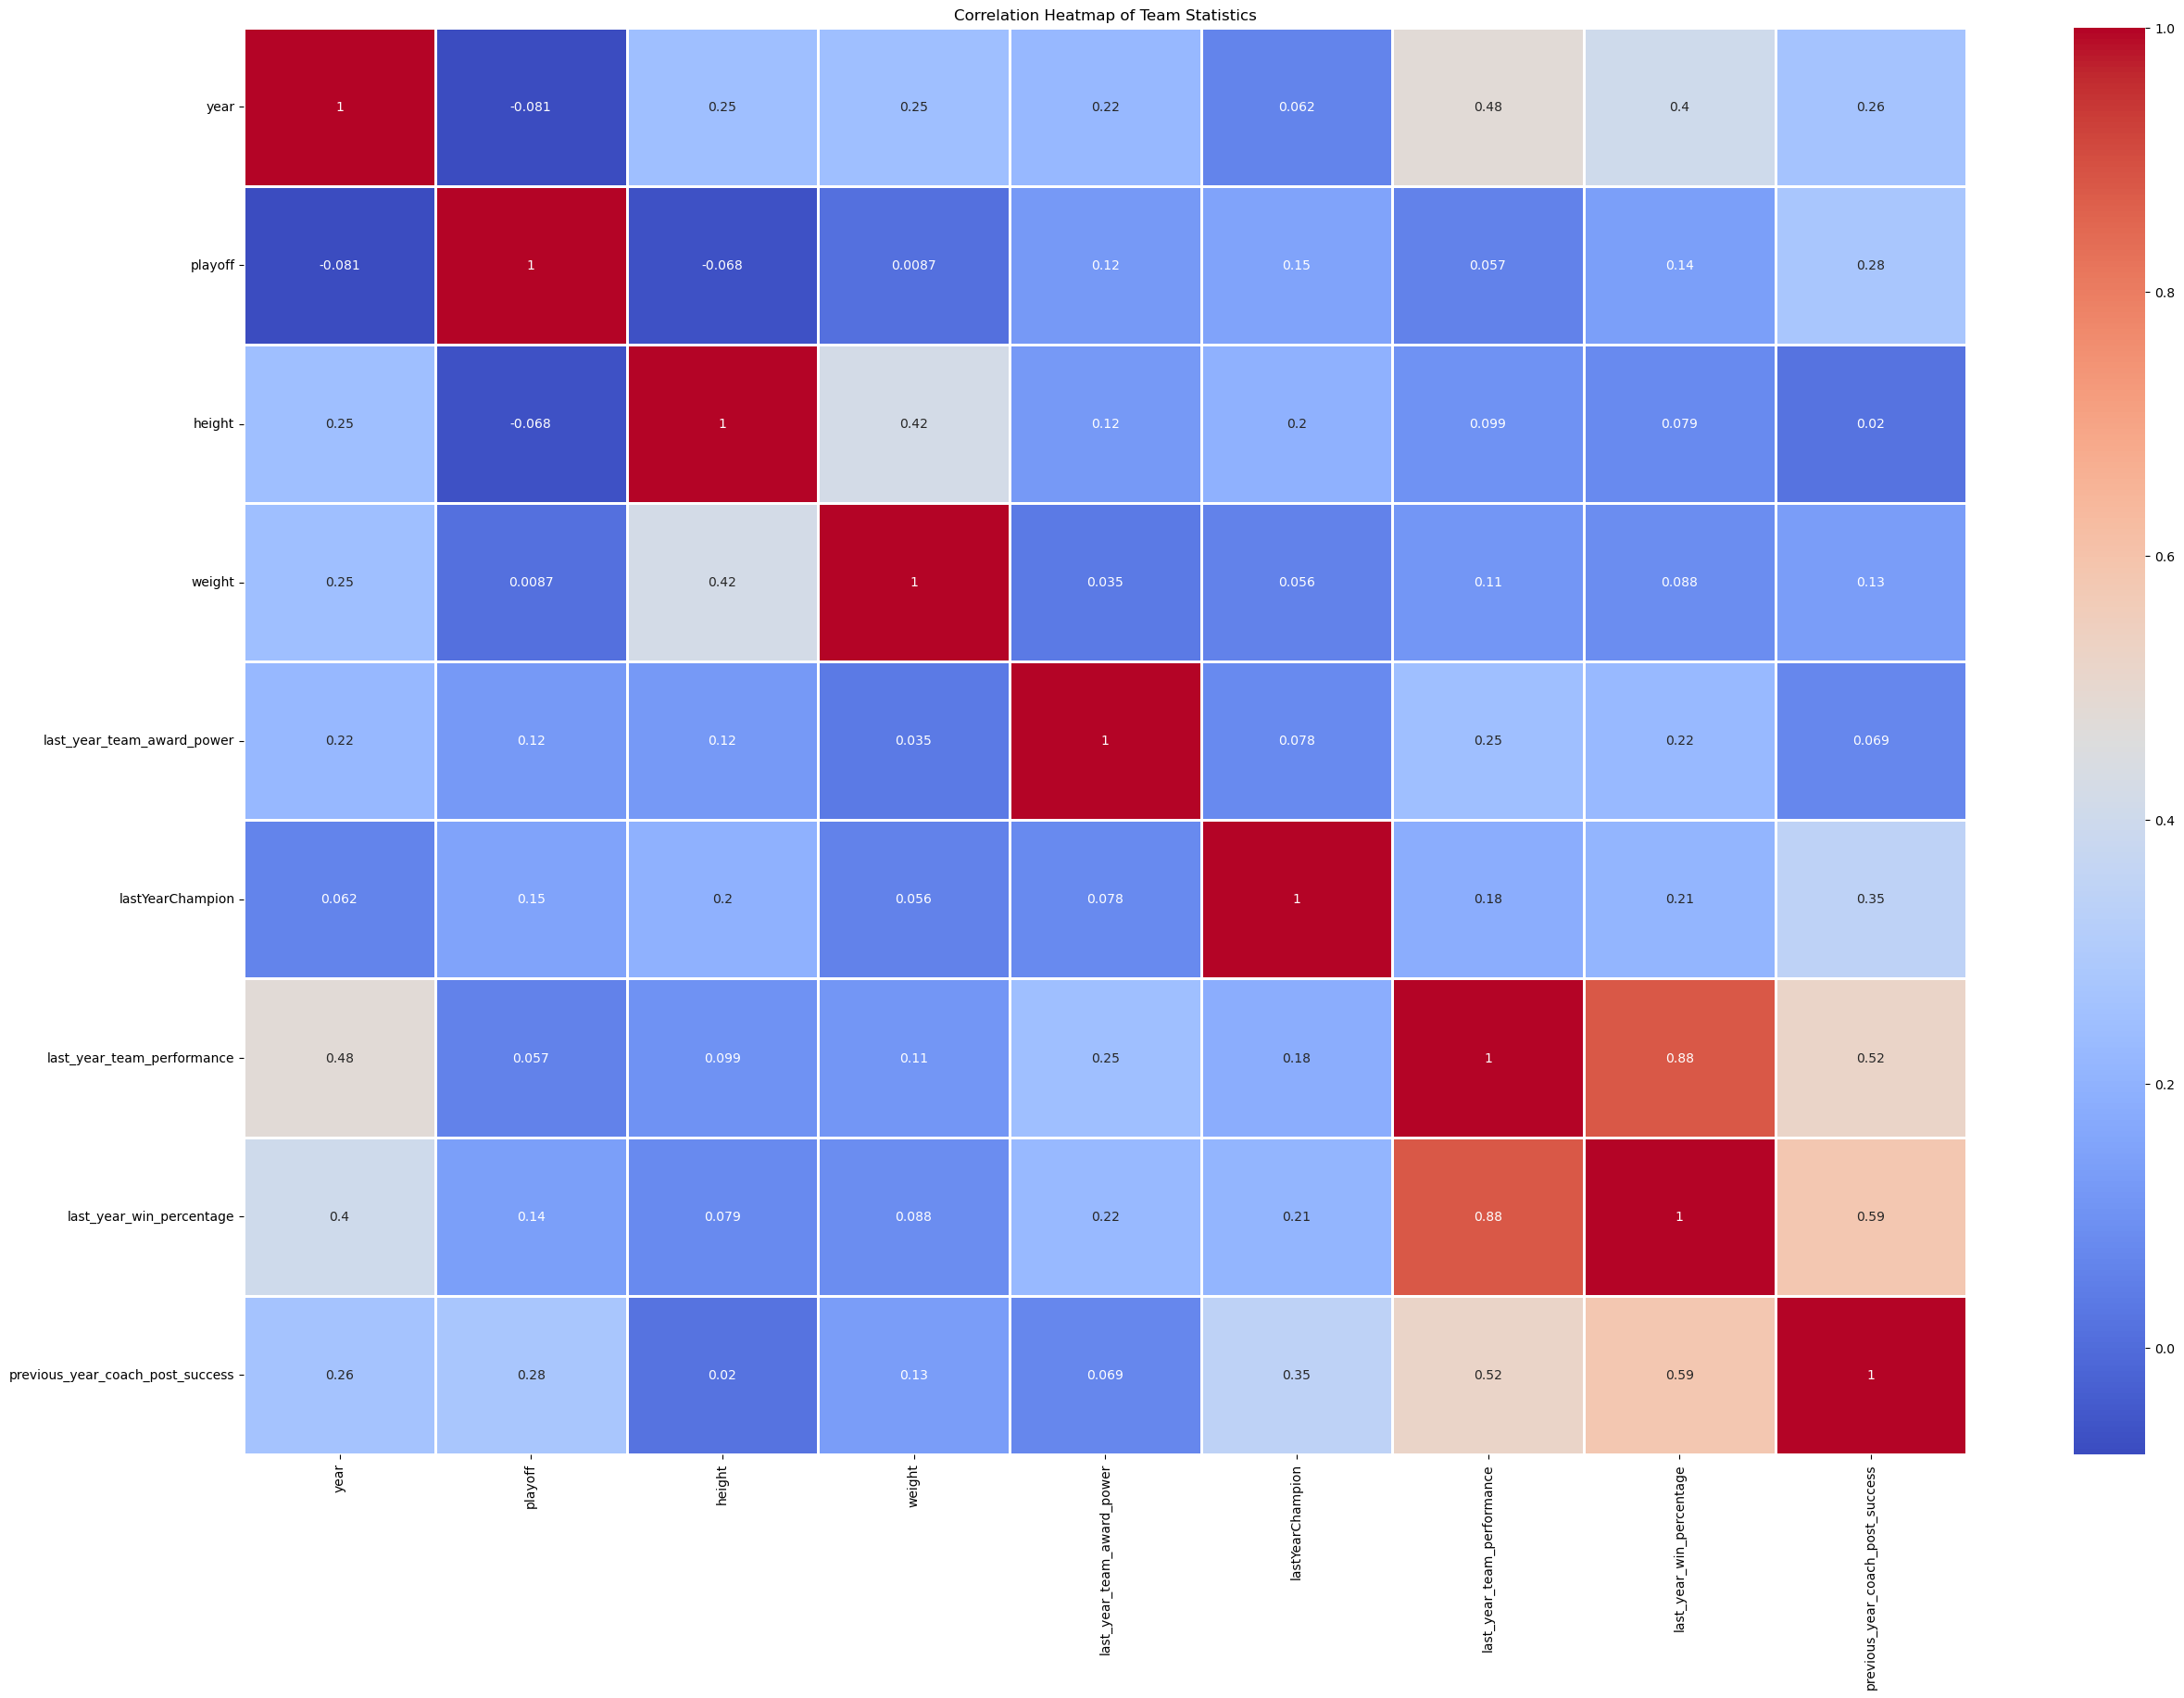

In [113]:
# Drop Redundancy

team_performance = team_performance.drop(columns=['coachWinRate', 'homeWinRate', 'avgAttendance','confWinPercentage'])



data_numeric=team_performance.select_dtypes(['number'])
correlation_matrix = data_numeric.corr()


plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", linewidths=1)
plt.title("Correlation Heatmap of Team Statistics")
plt.show()
team_performance.to_csv('featurePrep.csv', index=False)



In [114]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

last_year_features = ['last_year_team_award_power', 'last_year_team_performance', 
                      'last_year_win_percentage', 'previous_year_coach_post_success']

X_last_year = team_performance[last_year_features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_last_year)
pca = PCA(n_components=2)  
X_pca = pca.fit_transform(X_scaled)
team_performance['last_year_pca_1'] = X_pca[:, 0]
team_performance['last_year_pca_2'] = X_pca[:, 1]
team_performance = team_performance.drop(columns=last_year_features)
#team_performance.to_csv('featurePrep_with_pca.csv', index=False)
#print(team_performance[['tmID', 'year', 'last_year_pca_1', 'last_year_pca_2', 'playoff']].head())
print(team_performance.head())


   tmID  year confID  playoff     coachID  height  weight  lastYearChampion  \
3   CHA     1     EA        0  dunntr01wc    71.7   168.8                 0   
15  CLE     1     EA        1  hugheda99w    70.9   162.8                 0   
27  DET     1     EA        0  liebena01w    71.5   162.9                 0   
37  HOU     1     WE        1  chancva99w    72.1   166.2                 0   
46  IND     1     EA        0  donovan99w    72.3   168.0                 0   

    last_year_pca_1  last_year_pca_2  
3          3.466291          0.25411  
15         3.466291          0.25411  
27         3.466291          0.25411  
37         3.466291          0.25411  
46         3.466291          0.25411  


In [15]:
import pandas as pd
player_teams = pd.read_csv("../cleaned_datasets/players_teams_cleaned.csv")


TUL_players_year_11 = player_teams[(player_teams['tmID'] == 'TUL') & (player_teams['year'] == 11)]
TUL_players_last_year = player_teams[(player_teams['playerID'].isin(TUL_players_year_11['playerID'])) & (player_teams['year'] == 10)]
last_year_team_performance_TUL = TUL_players_last_year['Performance_Per_Game'].median()

print(TUL_players_last_year)
print(f"Last Year Team Performance (TUL): {last_year_team_performance_TUL}")


feature_prep = pd.read_csv('featurePrep.csv')
TUL_row = feature_prep[(feature_prep['tmID'] == 'TUL') & (feature_prep['year'] == 11)]
feature_prep.loc[(feature_prep['tmID'] == 'TUL') & (feature_prep['year'] == 11), 'last_year_team_performance'] = round(last_year_team_performance_TUL,1)
feature_prep.to_csv('featurePrep.csv', index=False)

print("Updated featurePrep.csv with TUL performance for Year 11.")



       playerID  year tmID  Performance_Per_Game
697   holtam01w    10  CON              6.956521
751  jacksti02w    10  NYL              6.205882
857   lacyje01w    10  ATL              2.625000
877  lattaiv01w    10  ATL              4.625000
902  lennobe01w    10  LAS              9.733333
Last Year Team Performance (TUL): 6.205882170415231
Updated featurePrep.csv with TUL performance for Year 11.


In [ ]:
import pandas as pd


award_values = {
    "Most Valuable Player": 10,
    "WNBA Finals Most Valuable Player": 9,
    "Coach of the Year": 1,
    "Defensive Player of the Year": 7,
    "All-Star Game Most Valuable Player": 6,
    "WNBA All-Decade Team": 5,
    "Most Improved Player": 4,
    "WNBA All Decade Team Honorable Mention": 3,
    "Rookie of the Year": 2,
    "Sixth Woman of the Year": 1,
    "Kim Perrot Sportsmanship Award": 0,
}

# Load the necessary datasets
player_teams = pd.read_csv("../cleaned_datasets/players_teams_cleaned.csv")
awards = pd.read_csv("../cleaned_datasets/awards_players_cleaned.csv")


decay_factor = 0.9
TUL_players_year_11 = player_teams[(player_teams['tmID'] == 'TUL') & (player_teams['year'] == 11)]
TUL_awards = awards[awards['playerID'].isin(TUL_players_year_11['playerID'])]
TUL_awards['adjusted_award_power'] = 0

for index, row in TUL_awards.iterrows():
    award = row['award']
    award_value = award_values.get(award, 0)
    years_since_award = 11 - row['year']
    adjusted_value = award_value * (decay_factor ** years_since_award)
    TUL_awards.loc[index, 'adjusted_award_power'] = adjusted_value

last_year_team_award_power_TUL = TUL_awards['adjusted_award_power'].sum()
feature_prep = pd.read_csv('featurePrep.csv')
feature_prep.loc[(feature_prep['tmID'] == 'TUL') & (feature_prep['year'] == 11), 'last_year_team_award_power'] = round(last_year_team_award_power_TUL,1)
feature_prep.to_csv('featurePrep.csv', index=False)


Last Year Team Award Power (TUL) with regression: 34.80222023190001
Updated featurePrep.csv with TUL award power for Year 11.


/var/folders/r3/3bq7njsx1kd2kllbx_2c8n6h0000gn/T/ipykernel_66948/1310647753.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  TUL_awards['adjusted_award_power'] = 0


In [29]:
import pandas as pd

# Read the data
player_teams = pd.read_csv("../cleaned_datasets/players_teams_cleaned.csv")
feature_prep = pd.read_csv('featurePrep.csv')

TUL_players_year_11 = player_teams[(player_teams['tmID'] == 'TUL') & (player_teams['year'] == 11)]
TUL_players_last_year = player_teams[(player_teams['playerID'].isin(TUL_players_year_11['playerID'])) & (player_teams['year'] == 10)]
previous_teams = TUL_players_last_year['tmID'].unique()
previous_teams_win_percentage = feature_prep[feature_prep['tmID'].isin(previous_teams) & (feature_prep['year'] == 10)]['last_year_win_percentage'].mean()
if pd.isna(previous_teams_win_percentage):
    previous_teams_win_percentage = -1
feature_prep.loc[(feature_prep['tmID'] == 'TUL') & (feature_prep['year'] == 11), 'last_year_win_percentage'] = round(previous_teams_win_percentage,1)
feature_prep.to_csv('featurePrep.csv', index=False)




In [6]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


feature_prep = pd.read_csv('featurePrep.csv')

print(feature_prep.head())

required_columns = ['last_year_team_award_power', 'last_year_team_performance', 
                    'last_year_win_percentage', 'previous_year_coach_post_success',
                    'height', 'weight']

if all(col in feature_prep.columns for col in required_columns):
    print("All required columns are present.")
    X_last_year = feature_prep[required_columns]
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_last_year)
    pca = PCA(n_components=3)
    X_pca = pca.fit_transform(X_scaled)
    feature_prep['last_year_pca_1'] = X_pca[:, 0]
    feature_prep['last_year_pca_2'] = X_pca[:, 1]
    feature_prep['last_year_pca_3'] = X_pca[:, 2]

    feature_prep = feature_prep.drop(columns=required_columns)
    feature_prep.to_csv('featurePrep_with_pca.csv', index=False)
    print("Updated featurePrep with PCA:")
    print(feature_prep.head())

else:
    print("Missing required columns in featurePrep.csv.")


  tmID  year confID  playoff     coachID  height  weight  \
0  CHA     1     EA        0  dunntr01wc    71.7   168.8   
1  CLE     1     EA        1  hugheda99w    70.9   162.8   
2  DET     1     EA        0  liebena01w    71.5   162.9   
3  HOU     1     WE        1  chancva99w    72.1   166.2   
4  IND     1     EA        0  donovan99w    72.3   168.0   

   last_year_team_award_power  lastYearChampion  last_year_team_performance  \
0                        -1.0                 0                        -1.0   
1                        -1.0                 0                        -1.0   
2                        -1.0                 0                        -1.0   
3                        -1.0                 0                        -1.0   
4                        -1.0                 0                        -1.0   

   last_year_win_percentage  previous_year_coach_post_success  
0                      -1.0                              -1.0  
1                      -1.0         

In [19]:
import pandas as pd

# Load your dataset
df = pd.read_csv("featurePrep_with_pca.csv")

# Initialize an empty list to store the playoff teams that passed in both current and previous year
playoff_teams_per_year_filtered = []

# Loop through the years and filter teams that passed the playoffs and were in the previous year's playoffs
years = sorted(df['year'].unique())  # Get sorted list of years
previous_year_teams = set()  # Initialize an empty set for previous year playoff teams

for year in years:
    # Filter teams that passed to the playoffs in the current year (playoff == 1)
    current_year_playoffs = df[(df['year'] == year) & (df['playoff'] == 1)]
    
    # Filter teams that also passed to the playoffs in the previous year
    if year > 1:  # Skip for the first year, since there is no previous year
        current_year_filtered = current_year_playoffs[current_year_playoffs['tmID'].isin(previous_year_teams)]
    else:
        current_year_filtered = pd.DataFrame(columns=df.columns)  # No teams to filter for the first year
    
    # Add the filtered teams for the current year to the result
    playoff_teams_per_year_filtered.append({'year': year, 'tmID': current_year_filtered['tmID'].tolist()})
    
    # Update previous_year_teams with the current year's teams
    previous_year_teams = set(current_year_playoffs['tmID'])

# Convert the result to a DataFrame
playoff_teams_per_year_filtered_df = pd.DataFrame(playoff_teams_per_year_filtered)

# Display the result
print(playoff_teams_per_year_filtered_df)


    year                                 tmID
0      1                                   []
1      2            [CLE, HOU, LAS, NYL, SAC]
2      3            [CHA, HOU, LAS, NYL, UTA]
3      4                      [CHA, HOU, LAS]
4      5            [CON, DET, LAS, MIN, SAC]
5      6       [CON, DET, LAS, NYL, SAC, SEA]
6      7  [CON, DET, HOU, IND, LAS, SAC, SEA]
7      8            [CON, DET, IND, SAC, SEA]
8      9  [CON, DET, IND, NYL, SAC, SAS, SEA]
9     10            [DET, IND, LAS, SAS, SEA]
10    11                                   []


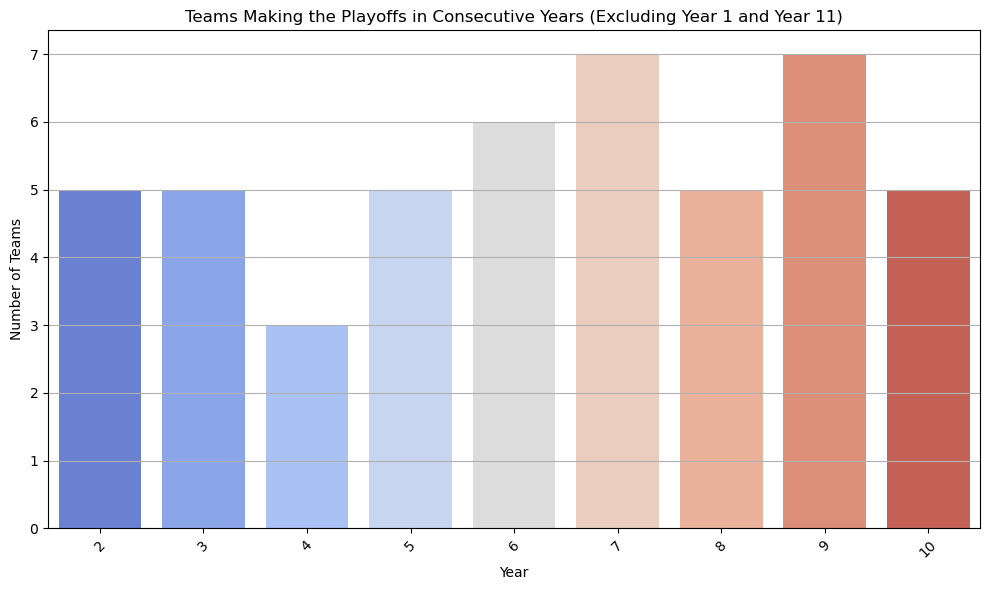

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming 'playoff_teams_per_year_filtered_df' contains the teams that passed in both years
# Filter out year 1 and year 11
filtered_df = playoff_teams_per_year_filtered_df[~playoff_teams_per_year_filtered_df['year'].isin([1, 11])]

# Create a new DataFrame with the number of teams that made playoffs in the filtered years
teams_playoffs = []

# Loop through each year's data to count the teams that passed the playoffs in both years
for idx, row in filtered_df.iterrows():
    year = row['year']
    tmID_list = row['tmID']
    
    # Count how many teams made the playoffs in this year
    num_teams = len(tmID_list)
    
    teams_playoffs.append({'year': year, 'num_teams': num_teams})

# Convert the data to a DataFrame
teams_playoffs_df = pd.DataFrame(teams_playoffs)

# Plot the number of teams making the playoffs in consecutive years
plt.figure(figsize=(10, 6))
sns.barplot(x='year', y='num_teams', data=teams_playoffs_df, palette='coolwarm')

plt.title('Teams Making the Playoffs in Consecutive Years (Excluding Year 1 and Year 11)')
plt.xlabel('Year')
plt.ylabel('Number of Teams')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()


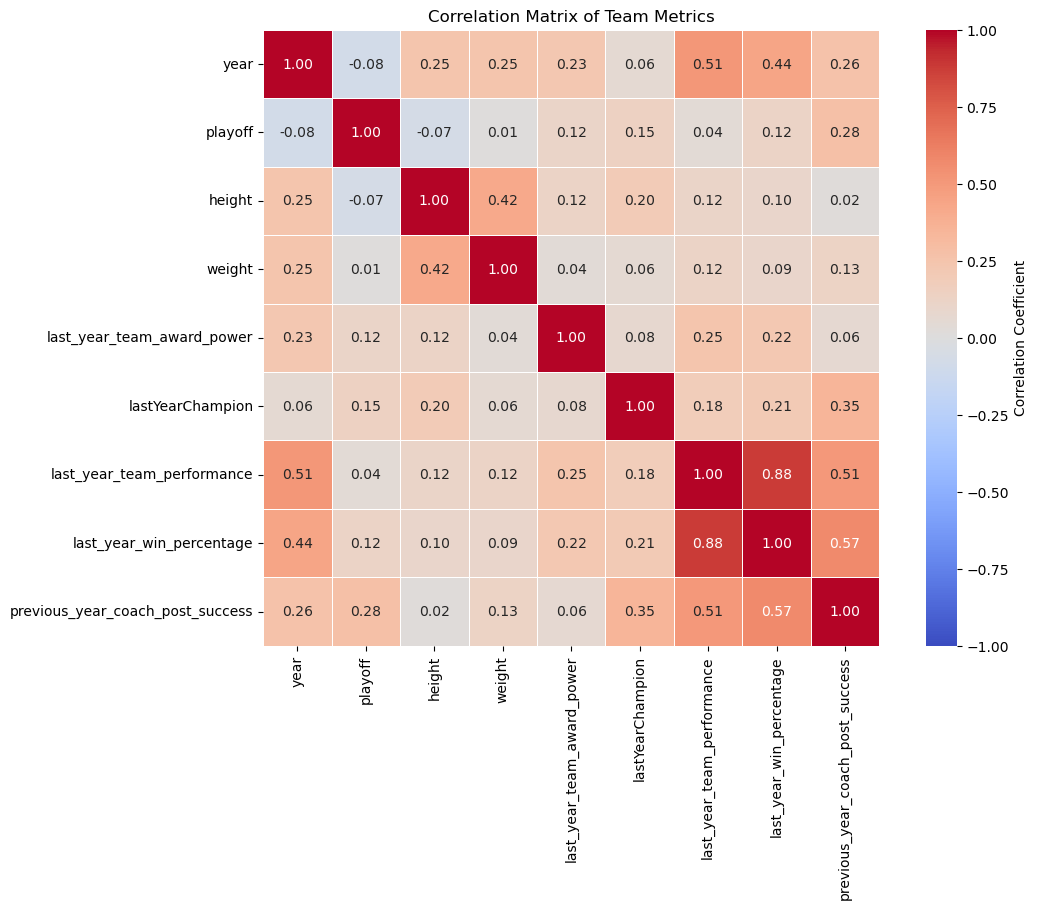

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("featurePrep.csv")

# Select only the numeric columns (ignore categorical ones like 'tmID', 'coachID', etc.)
numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

# Calculate the correlation matrix for the selected numeric columns
corr_matrix = df[numeric_columns].corr()

# Plot the correlation matrix using a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',  # Format the numbers to 2 decimal places
    cmap='coolwarm',  # Color scheme
    vmin=-1, vmax=1,  # Set the range of correlation values
    cbar_kws={'label': 'Correlation Coefficient'},  # Colorbar label
    square=True,  # Make the heatmap square-shaped
    linewidths=0.5  # Add lines between cells for readability
)

plt.title('Correlation Matrix of Team Metrics')
plt.show()